In [1]:
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

from astropy.io import fits
import glob
from scipy import stats
from scipy.stats import norm
import os

In [2]:
def fits_file_stack (fits_files):
    ###input: using glob, we take several files of same category/time
    ###output: master, master axix=0 (pixel), the original stack
    files= sorted(glob.glob(fits_files))
    print(f'found {len(files)} files')
    frames = []
    for file in files:
            with fits.open(file) as hdul:
                data= hdul[0].data.astype(float)
                frames.append(data)

            stack= np.array(frames)
            print('Stack Shape:', stack.shape)
            master= np.median(stack, axis=0)
            pixels= master.flatten()
            return master,pixels, stack

In [3]:
master_dark_2s, _ , _= fits_file_stack("lab3/darks/Dark-2s-*")
master_dark_4s , _ ,_ = fits_file_stack("lab3/darks/Dark-4s-*")
master_dark_17s,_,_= fits_file_stack("lab3/darks/Dark-17s-*")
master_dark_45s,_,_= fits_file_stack("lab3/darks/Dark-45s-*")

found 10 files
Stack Shape: (1, 261, 390)
found 10 files
Stack Shape: (1, 261, 390)
found 10 files
Stack Shape: (1, 261, 390)
found 18 files
Stack Shape: (1, 262, 392)


In [4]:
# Configuration
output_dir = "dark_corrected_lab3"
prefix = "dark_corr_"
os.makedirs(output_dir, exist_ok=True)

# List of patterns to match B, V, and Standard star images
patterns = [
    "lab3/Science_Image/-B-45s-*",
    "lab3/Science_Image/-V-45s-*",
    "lab3/Science_Image/SA101-B-45s-*"
]

for pattern in patterns:
    file_list = glob.glob(pattern)

    for file_path in file_list:
        with fits.open(file_path) as hdul:
            data = hdul[0].data
            header = hdul[0].header

            # Apply the dark subtraction
            reduced_data = data - master_dark_45s

            # Update history for the lab record
            header['HISTORY'] = "Dark subtraction applied using master_dark_45s"

            # Construct the new filename
            base_name = os.path.basename(file_path)
            output_path = os.path.join(output_dir, f"{prefix}{base_name}")

            # Save the file
            fits.writeto(output_path, reduced_data, header, overwrite=True)

print(f"images are in the folder: {output_dir}")

images are in the folder: dark_corrected_lab3


In [5]:
#Same thing for flats

output_dir = "dark_corrected_flats_lab3"
os.makedirs(output_dir, exist_ok=True)

flat_jobs = [
    {"pattern": "lab3/Flats/Flat-B-17s-*", "dark": master_dark_17s},
    {"pattern": "lab3/Flats/Flat-V-4s-*", "dark": master_dark_4s},
    {"pattern": "lab3/Flats/Flat-R-2s-*", "dark": master_dark_2s}
]

for job in flat_jobs:
    file_list = glob.glob(job["pattern"])
    print(f"Processing {len(file_list)} files for pattern: {job['pattern']}")

    for file_path in file_list:
        with fits.open(file_path) as hdul:
            data = hdul[0].data
            header = hdul[0].header

            corrected_data = data - job["dark"]

            header['HISTORY'] = "Dark subtraction applied to flat"

            base_name = os.path.basename(file_path)
            output_path = os.path.join(output_dir, f"dark_corr_{base_name}")

            fits.writeto(output_path, corrected_data, header, overwrite=True)

print("flats calibrated.")

Processing 5 files for pattern: lab3/Flats/Flat-B-17s-*
Processing 5 files for pattern: lab3/Flats/Flat-V-4s-*
Processing 5 files for pattern: lab3/Flats/Flat-R-2s-*
flats calibrated.


In [6]:
master_flat_B = fits_file_stack("dark_corrected_flats_lab3/dark_corr_Flat-B-*")
master_flat_R = fits_file_stack("dark_corrected_flats_lab3/dark_corr_Flat-R-*")
master_flat_V = fits_file_stack("dark_corrected_flats_lab3/dark_corr_Flat-V-*")
norm_flat_B = master_flat_B[0] / np.median(master_flat_B[0])
norm_flat_V = master_flat_V[0] / np.median(master_flat_V[0])
norm_flat_R = master_flat_R[0] / np.median(master_flat_R[0])


found 5 files
Stack Shape: (1, 261, 390)
found 5 files
Stack Shape: (1, 261, 390)
found 5 files
Stack Shape: (1, 261, 390)


In [7]:
#Flat calibration

# 1. Configuration
final_output_dir = "final_calibrated_lab3"
os.makedirs(final_output_dir, exist_ok=True)

# 2. Get the list of dark-corrected science images
# This includes M67 and the SA101 standard stars
science_to_calibrate = glob.glob("dark_corrected_lab3/dark_corr_*")

print(f"Starting final calibration for {len(science_to_calibrate)} files...")

for file_path in science_to_calibrate:
    with fits.open(file_path) as hdul:
        data = hdul[0].data
        header = hdul[0].header
        fname = os.path.basename(file_path)

        # 3. Determine which normalized flat to use
        if "-B-" in fname:
            flat = norm_flat_B
            filter_name = "B"
        elif "-V-" in fname:
            flat = norm_flat_V
            filter_name = "V"
        elif "-R-" in fname:
            flat = norm_flat_R
            filter_name = "R"
        else:
            print(f"Skipping {fname}: No filter match.")
            continue

        # 4. For some odd reason, the flat has a couple pixels less than the science image. I am cropping so they match
        # Find the smallest dimensions common to both the image and the flat
        min_rows = min(data.shape[0], flat.shape[0])
        min_cols = min(data.shape[1], flat.shape[1])

        # slice both to match
        data_cropped = data[:min_rows, :min_cols]
        flat_cropped = flat[:min_rows, :min_cols]

        # 5. Perform Division (Science / Flat)
        # use np.where to avoid dividing by zero if the flat has 0-value pixels
        calibrated_data = np.divide(data_cropped, flat_cropped,
                                    out=np.zeros_like(data_cropped),
                                    where=flat_cropped!=0)

        # 6. Update Header & Save
        header['HISTORY'] = f"Flat-fielded with norm_flat_{filter_name}"
        header['HISTORY'] = f"Cropped to {min_rows}x{min_cols} to match flat size"
        header['CALI'] = True

        output_path = os.path.join(final_output_dir, f"calib_{fname}")
        fits.writeto(output_path, calibrated_data, header, overwrite=True)

print(f"calibrated images are in: {final_output_dir}")

Starting final calibration for 40 files...
calibrated images are in: final_calibrated_lab3


In [8]:
import astroalign as aa


# 1. SET  MASTER REFERENCE
ref_path = "final_calibrated_lab3/calib_dark_corr_-B-45s-0C-20260409-020247.fits"

with fits.open(ref_path) as hdul:
    ref_data = hdul[0].data.astype(float)

output_dir = "aligned_science_lab3"
os.makedirs(output_dir, exist_ok=True)

# 3. List all B and V calibrated science images
files_to_align = glob.glob("final_calibrated_lab3/calib_dark_corr_-*")

print(f"Using {os.path.basename(ref_path)} as the Master Reference.")

for file_path in files_to_align:
    fname = os.path.basename(file_path)

    with fits.open(file_path) as hdul:
        source_data = hdul[0].data.astype(float)
        header = hdul[0].header

        # dont touch ref file
        if file_path == ref_path:
            output_path = os.path.join(output_dir, f"aligned_{fname}")
            fits.writeto(output_path, source_data, header, overwrite=True)
            print(f"Saved reference image: {fname}")
            continue

        try:
            # 4. The Alignment Step
            # registered_data is the misalligned image.
            # footprint shows which pixels have valid data after the shift.
            registered_data, footprint = aa.register(source_data, ref_data)

            # Update header
            header['ALIGNED'] = True
            header['REF_FILE'] = os.path.basename(ref_path)

            output_path = os.path.join(output_dir, f"aligned_{fname}")
            fits.writeto(output_path, registered_data, header, overwrite=True)
            print(f"Successfully aligned: {fname}")

        except aa.MaxIterError:
            print(f"!! Failed to align {fname}: Not enough star matches.")
        except Exception as e:
            print(f"!! Error processing {fname}: {e}")



Using calib_dark_corr_-B-45s-0C-20260409-020247.fits as the Master Reference.
Successfully aligned: calib_dark_corr_-B-45s--1C-20260409-020550.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-020247.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-020333.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-020504.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-020636.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-020807.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-020853.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-020938.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-021024.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-021110.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-021156.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-021241.fits
Successfully aligned: calib_dark_corr_-B-45s-0C-20260409-021327.fits
Successfully aligned: ca

found 15 files
Stack Shape: (1, 261, 390)
found 15 files
Stack Shape: (1, 261, 390)


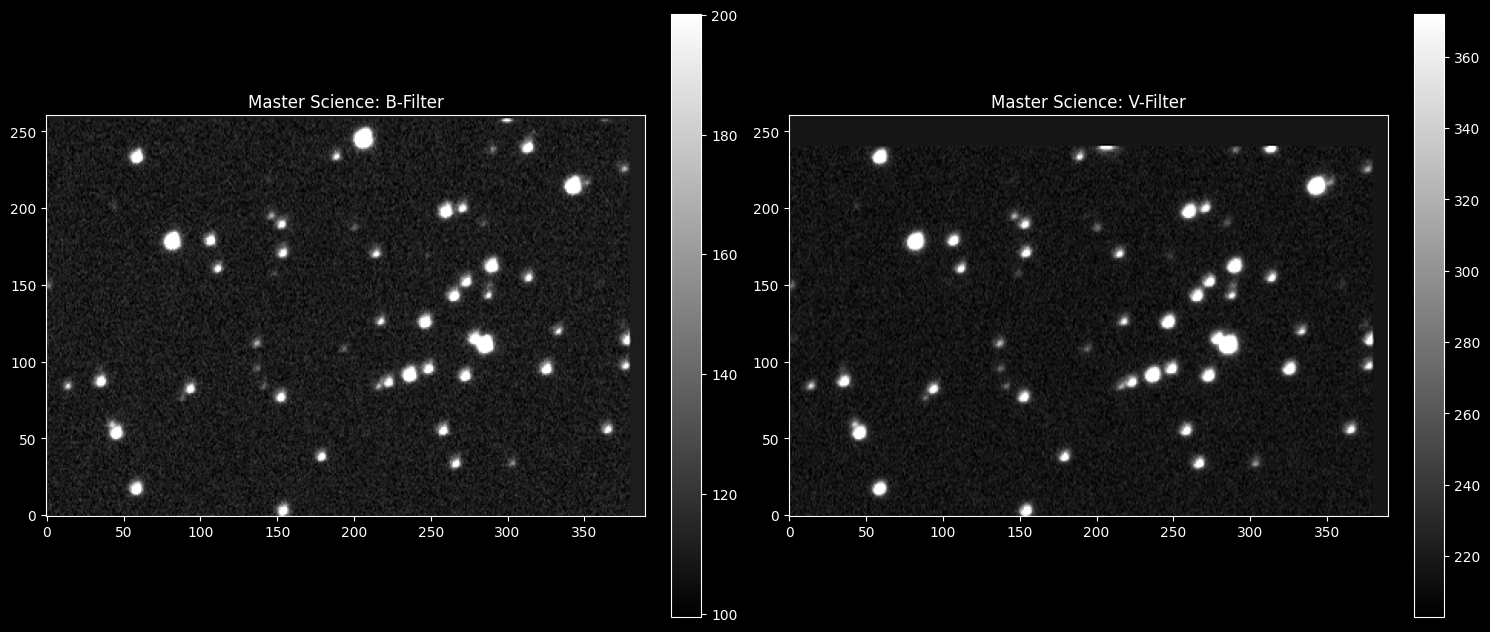

In [9]:
# Create Master B Stack
master_B, pixels_B, stack_B = fits_file_stack("aligned_science_lab3/aligned_calib_dark_corr_-B-*")
fits.writeto("master_Science_B.fits", master_B, overwrite=True)

# Create Master V Stack
master_V, pixels_V, stack_V = fits_file_stack("aligned_science_lab3/aligned_calib_dark_corr_-V-*")
fits.writeto("master_Science_V.fits", master_V, overwrite=True)

def visualize_results(data_b, data_v):
    fig, ax = plt.subplots(1, 2, figsize=(15, 7))

    # Calculate scaling based on percentiles for better contrast
    # This ignores the brightest 1% and darkest 1% of pixels
    def get_limits(data):
        vmin = np.percentile(data, 1)
        vmax = np.percentile(data, 99)
        return vmin, vmax

    # Plot Blue Master
    vmin_b, vmax_b = get_limits(data_b)
    im1 = ax[0].imshow(data_b, cmap='gray', vmin=vmin_b, vmax=vmax_b, origin='lower')
    ax[0].set_title("Master Science: B-Filter")
    fig.colorbar(im1, ax=ax[0], fraction=0.046, pad=0.04)

    # Plot Visual Master
    vmin_v, vmax_v = get_limits(data_v)
    im2 = ax[1].imshow(data_v, cmap='gray', vmin=vmin_v, vmax=vmax_v, origin='lower')
    ax[1].set_title("Master Science: V-Filter")
    fig.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# Run the visualization
visualize_results(master_B, master_V)



Found 48 stars in the cluster.


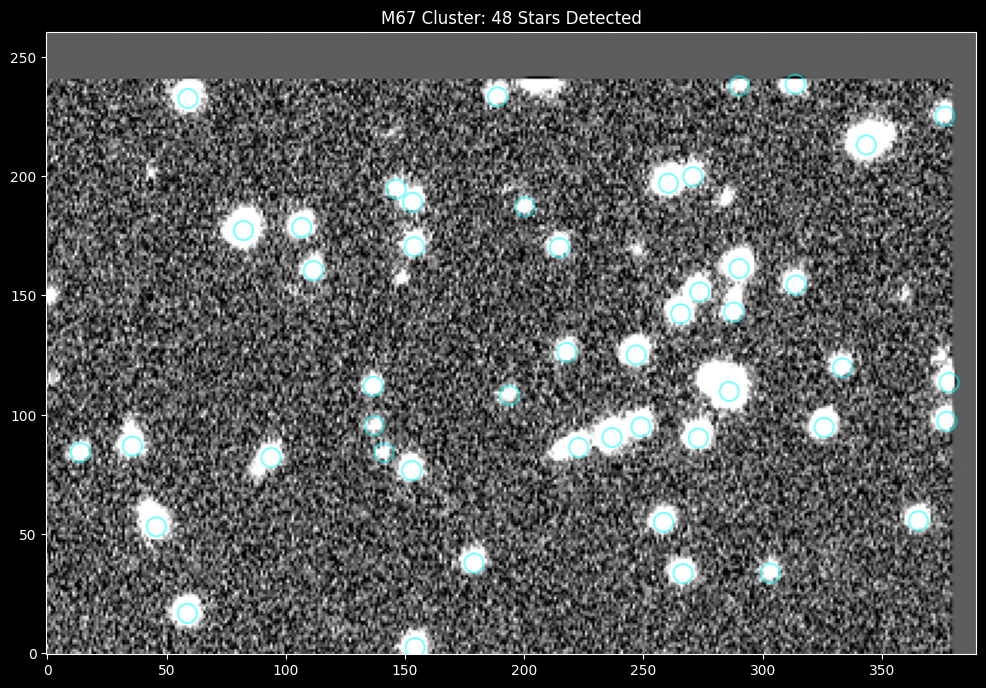

In [10]:
from photutils.detection import DAOStarFinder
from astropy.stats import mad_std
from photutils.aperture import CircularAperture, CircularAnnulus

# 1. Estimate background noise (sigma)
# We use master_V
bkg_sigma = mad_std(master_V)

# 2. find stars
daofind = DAOStarFinder(fwhm=3.0, threshold=5.*bkg_sigma)
sources = daofind(master_V)

print(f"Found {len(sources)} stars in the cluster.")

# 4. Create Apertures for visualization
positions = np.transpose((sources['x_centroid'], sources['y_centroid']))
apertures = CircularAperture(positions, r=4.0) # Inner circle
annulus_apertures = CircularAnnulus(positions, r_in=10.0, r_out=15.0) # The Donut

# 5. Plot the result
plt.figure(figsize=(12, 10))
plt.imshow(master_V, cmap='gray', origin='lower',
           vmin=np.percentile(master_V, 5), vmax=np.percentile(master_V, 95))

# Draw the apertures in cyan
apertures.plot(color='cyan', lw=1.5, alpha=0.5)
plt.title(f"M67 Cluster: {len(sources)} Stars Detected")
plt.show()

  21 |        -11.920 |   286.0 |   109.8
   35 |        -11.629 |    82.3 |   177.2
   42 |        -11.580 |   343.5 |   213.1
   14 |        -10.878 |   236.8 |    90.4
   44 |        -10.743 |    59.0 |   232.5

Photometry complete for 48 stars.


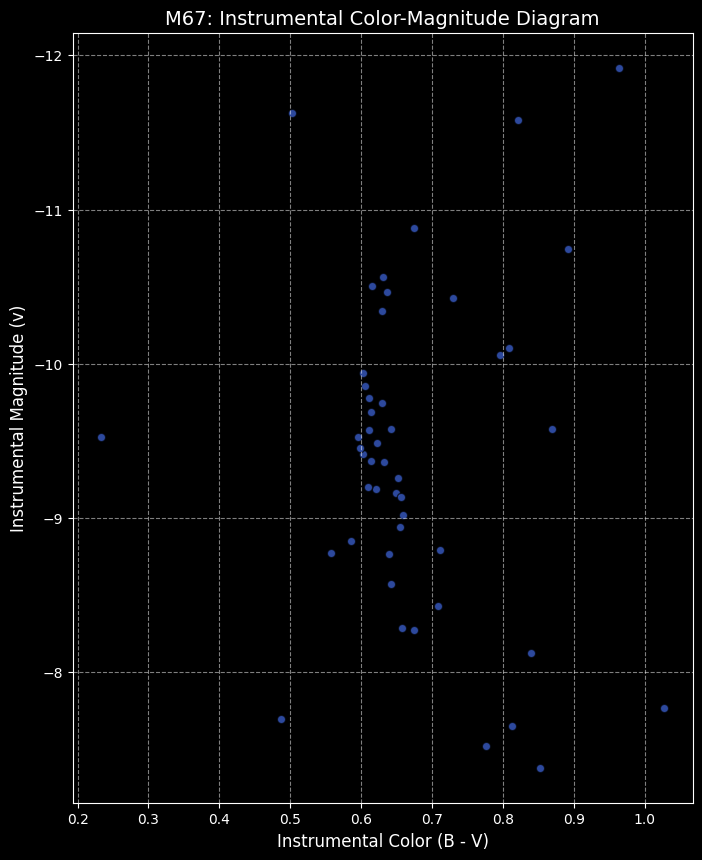

In [11]:
from photutils.aperture import aperture_photometry, ApertureStats

# 1. Perform Photometry on the V-band Master
v_table = aperture_photometry(master_V, apertures)
v_stats = ApertureStats(master_V, annulus_apertures)

# Local Background Subtraction for V
# (Total aperture sum) - (Median background per pixel * Area of the aperture)
v_flux = v_table['aperture_sum'] - (v_stats.median * apertures.area)

# 2. Perform Photometry on the B-band Master (using the SAME apertures)
b_table = aperture_photometry(master_B, apertures)
b_stats = ApertureStats(master_B, annulus_apertures)

# Local Background Subtraction for B
b_flux = b_table['aperture_sum'] - (b_stats.median * apertures.area)

# 3. Convert Flux to Instrumental Magnitudes
v_mag_inst = -2.5 * np.log10(np.where(v_flux > 0, v_flux, np.nan))
b_mag_inst = -2.5 * np.log10(np.where(b_flux > 0, b_flux, np.nan))

# 4. Calculate Color Index (B - V)
b_v_color = b_mag_inst - v_mag_inst

print(f"Photometry complete for {len(v_mag_inst)} stars.")

plt.figure(figsize=(8, 10))
plt.scatter(b_v_color, v_mag_inst, color='royalblue', edgecolor='k', alpha=0.7)

# IMPORTANT: Invert Y-axis because smaller magnitudes = brighter stars
plt.gca().invert_yaxis()

plt.xlabel("Instrumental Color (B - V)", fontsize=12)
plt.ylabel("Instrumental Magnitude (v)", fontsize=12)
plt.title("M67: Instrumental Color-Magnitude Diagram", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Sanders 70 identified at index: 35
Zero-Point V: 23.151, Zero-Point B: 23.086
Distance Modulus applied: 9.647


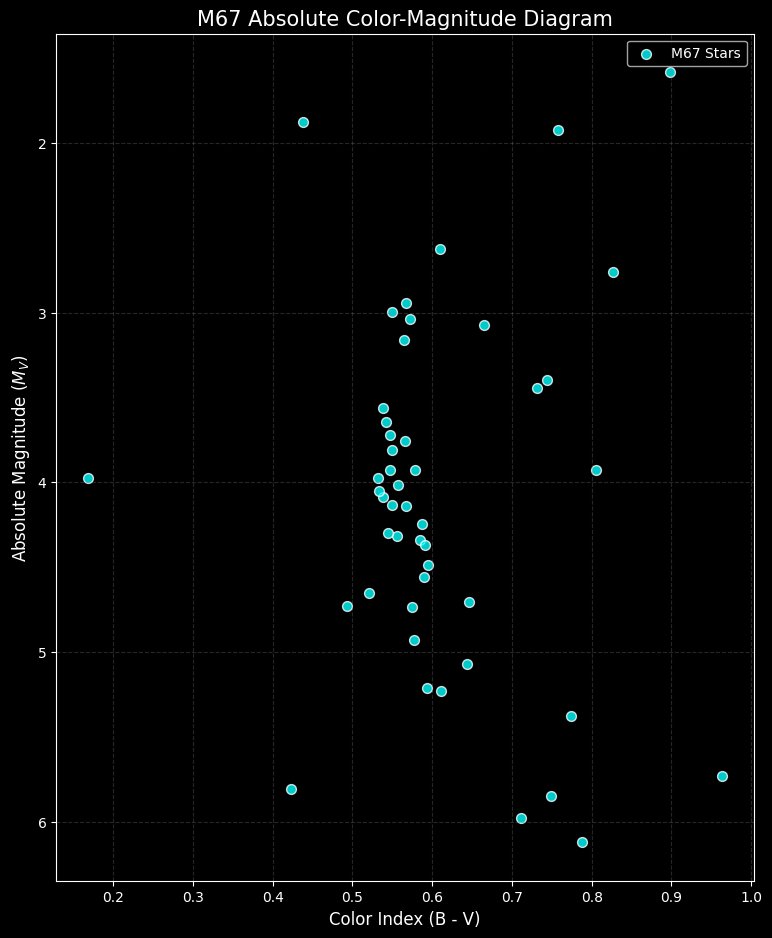

In [12]:
# REFERENCE VALUES
v_std_s70 = 11.522
b_std_s70 = 11.96
dist_m67 = 850  # Distance in parsecs
# Distance Modulus (m - M) = 5 * log10(d) - 5
dist_mod = 5 * np.log10(dist_m67) - 5

target_x, target_y = 70, 180

#APERTURE PHOTOMETRY
# Measure V-band Flux
v_table = aperture_photometry(master_V, apertures)
v_stats = ApertureStats(master_V, annulus_apertures)
v_flux = v_table['aperture_sum'] - (v_stats.median * apertures.area)

# Measure B-band Flux
b_table = aperture_photometry(master_B, apertures)
b_stats = ApertureStats(master_B, annulus_apertures)
b_flux = b_table['aperture_sum'] - (b_stats.median * apertures.area)

# Convert to Instrumental Magnitudes
v_mag_inst = -2.5 * np.log10(np.where(v_flux > 0, v_flux, np.nan))
b_mag_inst = -2.5 * np.log10(np.where(b_flux > 0, b_flux, np.nan))

s70_index = 35

# Calculate Zero-Point (ZP) Offsets
zp_v = v_std_s70 - v_mag_inst[s70_index]
zp_b = b_std_s70 - b_mag_inst[s70_index]

#4. DATA TRANSFORMATION
# Standard Apparent Magnitudes
v_mag_std = v_mag_inst + zp_v
b_mag_std = b_mag_inst + zp_b
b_v_std = b_mag_std - v_mag_std

# Absolute Magnitude (M_V)
v_abs_mag = v_mag_std - dist_mod

print(f"Sanders 70 identified at index: {s70_index}")
print(f"Zero-Point V: {zp_v:.3f}, Zero-Point B: {zp_b:.3f}")
print(f"Distance Modulus applied: {dist_mod:.3f}")

# 5. VISUALIZATION (THE HR DIAGRAM)
plt.figure(figsize=(9, 11), facecolor='black')
ax = plt.axes()
ax.set_facecolor('black')

# Plot the stars
plt.scatter(b_v_std, v_abs_mag, color='cyan', s=50, edgecolor='white', alpha=0.8, label='M67 Stars')

# Invert Y-axis: Brighter stars (lower magnitude) at the top
plt.gca().invert_yaxis()

# Labeling
plt.xlabel("Color Index (B - V)", color='white', fontsize=12)
plt.ylabel("Absolute Magnitude ($M_V$)", color='white', fontsize=12)
plt.title("M67 Absolute Color-Magnitude Diagram", color='white', fontsize=15)

# Formatting
plt.grid(color='gray', linestyle='--', alpha=0.3)
ax.tick_params(colors='white')
plt.legend(facecolor='black', labelcolor='white')

plt.show()

Isochrone file loaded


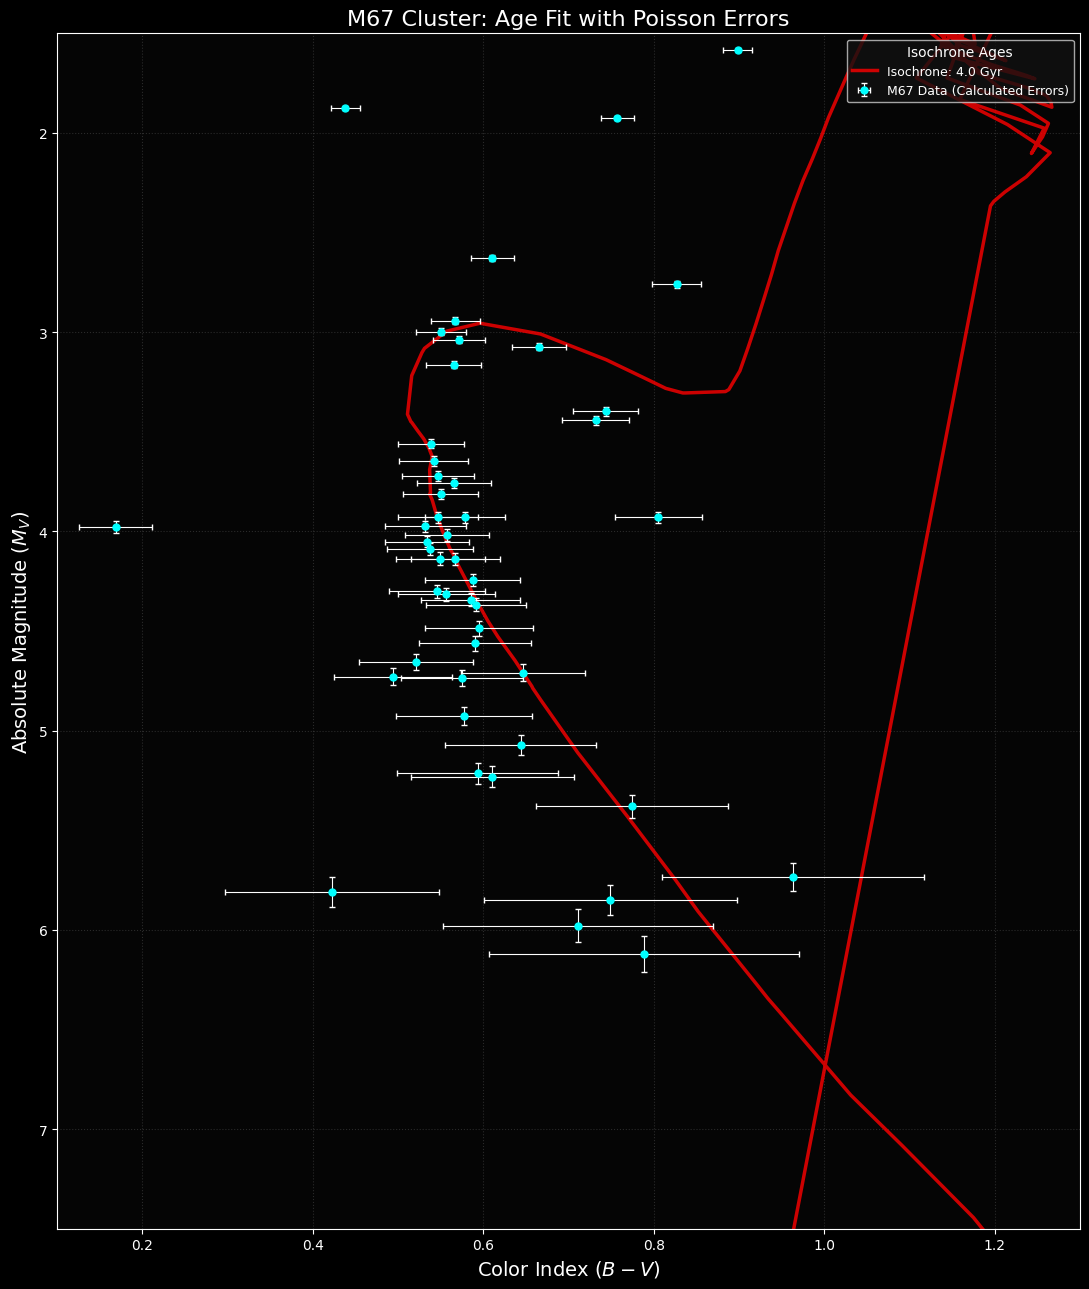

In [13]:
# CONFIGURATION & CAMERA PARAMETERS
iso_path = "isochone4.0e9.dat"
gain = 0.24286

#  CALCULATE SCIENTIFIC ERRORS
# Calculate error in Flux for V and B based on Poisson noise and background
# Error = sqrt(Flux/Gain + Area * Background_Sigma^2)
v_flux_err = np.sqrt(np.abs(v_flux) / gain + apertures.area * bkg_sigma**2)
b_flux_err = np.sqrt(np.abs(b_flux) / gain + apertures.area * bkg_sigma**2)

# Convert Flux Error to Magnitude Error using the 1.0857 constant
v_error = 1.0857 * (v_flux_err / np.abs(v_flux))
b_error = 1.0857 * (b_flux_err / np.abs(b_flux))

# Propagate error to Color (B-V)
bv_error = np.sqrt(b_error**2 + v_error**2)

#LOAD ISOCHRONE DATA
try:
    iso_data = np.genfromtxt(iso_path, names=True, skip_header=13, comments='#')
    print("Isochrone file loaded")
except Exception as e:
    print(f"Error loading file: {e}")

# THE PLOTTING ENGINE
plt.figure(figsize=(11, 13))
plt.gca().set_facecolor('#050505')

# A. Plot detected M67 stars with CALCULATED error bars
plt.errorbar(b_v_std, v_abs_mag, xerr=bv_error, yerr=v_error,
             fmt='o', color='cyan', ecolor='white', elinewidth=0.8,
             capsize=2, markersize=5, label='M67 Data (Calculated Errors)', zorder=5)

# C. Loop through isochrone ages (Raw Data)
log_ages = iso_data['logAge']
unique_log_ages = np.unique(log_ages)
colors = plt.cm.turbo(np.linspace(0, 1, len(unique_log_ages)))

for i, log_age in enumerate(unique_log_ages):
    mask = log_ages == log_age
    v_plot = iso_data['Vmag'][mask]
    color_plot = iso_data['Bmag'][mask] - iso_data['Vmag'][mask]

    linear_age = (10**log_age) / 1e9
    plt.plot(color_plot, v_plot, color="red",
             label=f'Isochrone: {linear_age:.1f} Gyr', linewidth=2.5, alpha=0.8)

# FORMATTING & DISPLAY
plt.gca().invert_yaxis()
plt.xlabel("Color Index $(B - V)$", fontsize=14, color='white')
plt.ylabel("Absolute Magnitude $(M_V)$", fontsize=14, color='white')
plt.title("M67 Cluster: Age Fit with Poisson Errors", fontsize=16, color='white')

# Zoom focus
plt.xlim(0.1, 1.3)
plt.ylim(7.5, 1.5)

plt.grid(color='gray', linestyle=':', alpha=0.3)
plt.legend(title="Isochrone Ages", loc='upper right', frameon=True,
           facecolor='#111111', labelcolor='white', fontsize=9)
plt.tick_params(colors='white')

plt.tight_layout()
plt.show()

In [14]:
import pandas as pd
#i just wanted a sample table this is written using gemini.

# 1. Create a DataFrame from your calculated variables
# We use the indices from your 'sources' table to keep track of Star IDs
data_summary = pd.DataFrame({
    'Star_Index': np.arange(len(v_mag_std)),
    'Apparent_Mag_V': v_mag_std,
    'Apparent_Mag_B': b_mag_std,
    'Color_Index_B_V': b_v_std,
    'Absolute_Mag_V': v_abs_mag,
    'V_Error': v_error,
    'B_V_Error': bv_error
})

# 2. Filter out any 'NaN' values (stars where flux was too low to calculate)
clean_data = data_summary.dropna().copy()

# 3. Sort by brightness (V magnitude) so the table is organized
clean_data = clean_data.sort_values('Apparent_Mag_V')

# 4. Display the top 15 stars (a good sample size for a poster)
print("TOP 15 SAMPLE STARS FOR POSTER")
print(clean_data.head(15).to_string(index=False))

# 5. Export to a CSV file so you can open it in Excel/Google Sheets
clean_data.to_csv("M67_star_data_summary.csv", index=False)
print("\nSuccess! Full data saved to 'M67_star_data_summary.csv'")

--- TOP 15 SAMPLE STARS FOR POSTER ---
 Star_Index  Apparent_Mag_V  Apparent_Mag_B  Color_Index_B_V  Absolute_Mag_V  V_Error  B_V_Error
         21       11.231001       12.129540         0.898539        1.583906 0.009136   0.016978
         35       11.522000       11.960000         0.438000        1.874905 0.010458   0.016855
         42       11.570845       12.328043         0.757198        1.923751 0.010698   0.019006
         14       12.272796       12.883169         0.610373        2.625702 0.014850   0.025259
         44       12.407637       13.234648         0.827011        2.760542 0.015822   0.028902
         32       12.589412       13.156443         0.567031        2.942317 0.017238   0.028976
          5       12.644264       13.194564         0.550300        2.997169 0.017691   0.029593
         40       12.685771       13.257528         0.571757        3.038676 0.018042   0.030391
          1       12.720626       13.386000         0.665374        3.073531 0.018343   

Isochrone file loaded successfully!


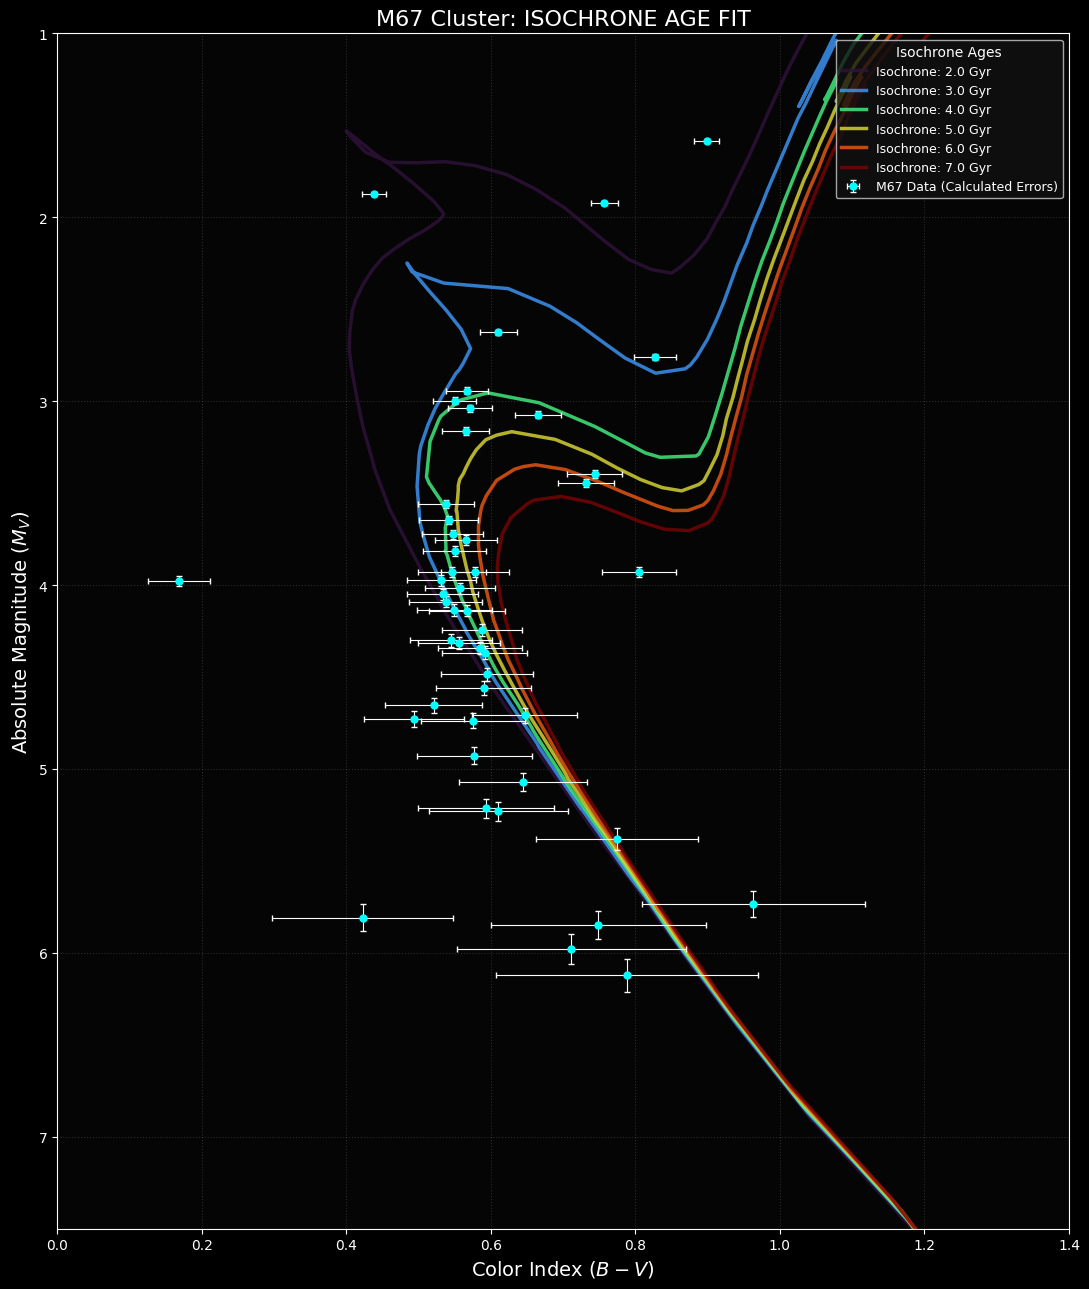

In [15]:
# CONFIGURATION & CAMERA PARAMETERS
iso_path = "isochrone2.dat.txt"
gain = 0.24286


# uncertainties using lecture 6 on w/ flux uncertainties
v_flux_err = np.sqrt(np.abs(v_flux) / gain + apertures.area * bkg_sigma**2)
b_flux_err = np.sqrt(np.abs(b_flux) / gain + apertures.area * bkg_sigma**2)

v_error = 1.0857 * (v_flux_err / np.abs(v_flux))
b_error = 1.0857 * (b_flux_err / np.abs(b_flux))
bv_error = np.sqrt(b_error**2 + v_error**2)

# LOAD ISOCHRONE DATA
try:
    iso_data = np.genfromtxt(iso_path, names=True, skip_header=13, comments='#')
    print("Isochrone file loaded successfully!")
except Exception as e:
    print(f"Error loading file: {e}")

plt.figure(figsize=(11, 13))
plt.gca().set_facecolor('#050505')

# A. Plot detected M67 stars
plt.errorbar(b_v_std, v_abs_mag, xerr=bv_error, yerr=v_error,
             fmt='o', color='cyan', ecolor='white', elinewidth=0.8,
             capsize=2, markersize=5, label='M67 Data (Calculated Errors)', zorder=5)

# C. Loop through isochrone ages with the "Loop-Fix" Filter
log_ages = iso_data['logAge']
unique_log_ages = np.unique(log_ages)
colors = plt.cm.turbo(np.linspace(0, 1, len(unique_log_ages)))

for i, log_age in enumerate(unique_log_ages):
    mask = (log_ages == log_age) & (iso_data['label'] <= 3)

    v_plot = iso_data['Vmag'][mask]
    color_plot = iso_data['Bmag'][mask] - iso_data['Vmag'][mask]

    linear_age = (10**log_age) / 1e9
    plt.plot(color_plot, v_plot, color=colors[i],
             label=f'Isochrone: {linear_age:.1f} Gyr', linewidth=2.5, alpha=0.8)

plt.gca().invert_yaxis()
plt.xlabel("Color Index $(B - V)$", fontsize=14, color='white')
plt.ylabel("Absolute Magnitude $(M_V)$", fontsize=14, color='white')
plt.title("M67 Cluster: ISOCHRONE AGE FIT", fontsize=16, color='white')

plt.xlim(0.0, 1.4)
plt.ylim(7.5, 1.0)

plt.grid(color='gray', linestyle=':', alpha=0.3)
plt.legend(title="Isochrone Ages", loc='upper right', frameon=True,
           facecolor='#111111', labelcolor='white', fontsize=9)
plt.tick_params(colors='white')

plt.tight_layout()
plt.show()

In [16]:
results = []


for log_age in unique_log_ages:
    mask = (log_ages == log_age) & (iso_data['label'] <= 3)
    iso_v = iso_data['Vmag'][mask]
    iso_color = iso_data['Bmag'][mask] - iso_data['Vmag'][mask]

    # Focus on the Age-Sensitive region (The Turn-Off)
    turnoff_mask = (v_abs_mag < 6.5) & (v_abs_mag > 1.0)

    residuals = []
    for s_c, s_m in zip(b_v_std[turnoff_mask], v_abs_mag[turnoff_mask]):
        if np.isnan(s_c): continue

        # Euclidean distance to the nearest isochrone point
        dist = np.sqrt((s_c - iso_color)**2 + (s_m - iso_v)**2)
        residuals.append(np.min(dist)**2)

    total_chi_sq = np.sum(residuals)
    age_gyr = (10**log_age) / 1e9
    results.append({'age_gyr': age_gyr, 'chi_sq': total_chi_sq})

# 2. ANALYZE RESULTS
score_df = pd.DataFrame(results)
min_score = score_df['chi_sq'].min()
best_fit_row = score_df.loc[score_df['chi_sq'].idxmin()]

# Define the 1-Sigma Threshold (Min Chi-Square + 1)
sigma_threshold = min_score + 1.0

# Find ages that fall within this threshold
within_sigma = score_df[score_df['chi_sq'] <= sigma_threshold]

lower_bound = within_sigma['age_gyr'].min()
upper_bound = within_sigma['age_gyr'].max()

# 3. PRINT THE SUMMARY CHART
print("\n" + "="*40)
print(f"{'Age (Gyr)':<15} | {'Chi-Square Score':<15}")
print("-" * 40)
for index, row in score_df.iterrows():
    marker = " <-- BEST FIT" if row['chi_sq'] == min_score else ""
    # Mark if it's within the 1-sigma bound
    if row['age_gyr'] >= lower_bound and row['age_gyr'] <= upper_bound and row['chi_sq'] != min_score:
        marker = " (Within 1-Sigma)"
    print(f"{row['age_gyr']:<15.2f} | {row['chi_sq']:<15.4f}{marker}")

print("-" * 40)
print(f"FINAL RESULT: {best_fit_row['age_gyr']:.2f} (+{upper_bound - best_fit_row['age_gyr']:.2f} / -{best_fit_row['age_gyr'] - lower_bound:.2f}) Gyr")
print("="*40)


Age (Gyr)       | Chi-Square Score
----------------------------------------
2.00            | 1.2584          (Within 1-Sigma)
3.00            | 0.9640          <-- BEST FIT
4.00            | 1.2035          (Within 1-Sigma)
5.00            | 1.3138          (Within 1-Sigma)
6.00            | 1.7619          (Within 1-Sigma)
7.00            | 2.0797         
----------------------------------------
FINAL RESULT: 3.00 (+3.00 / -1.00) Gyr


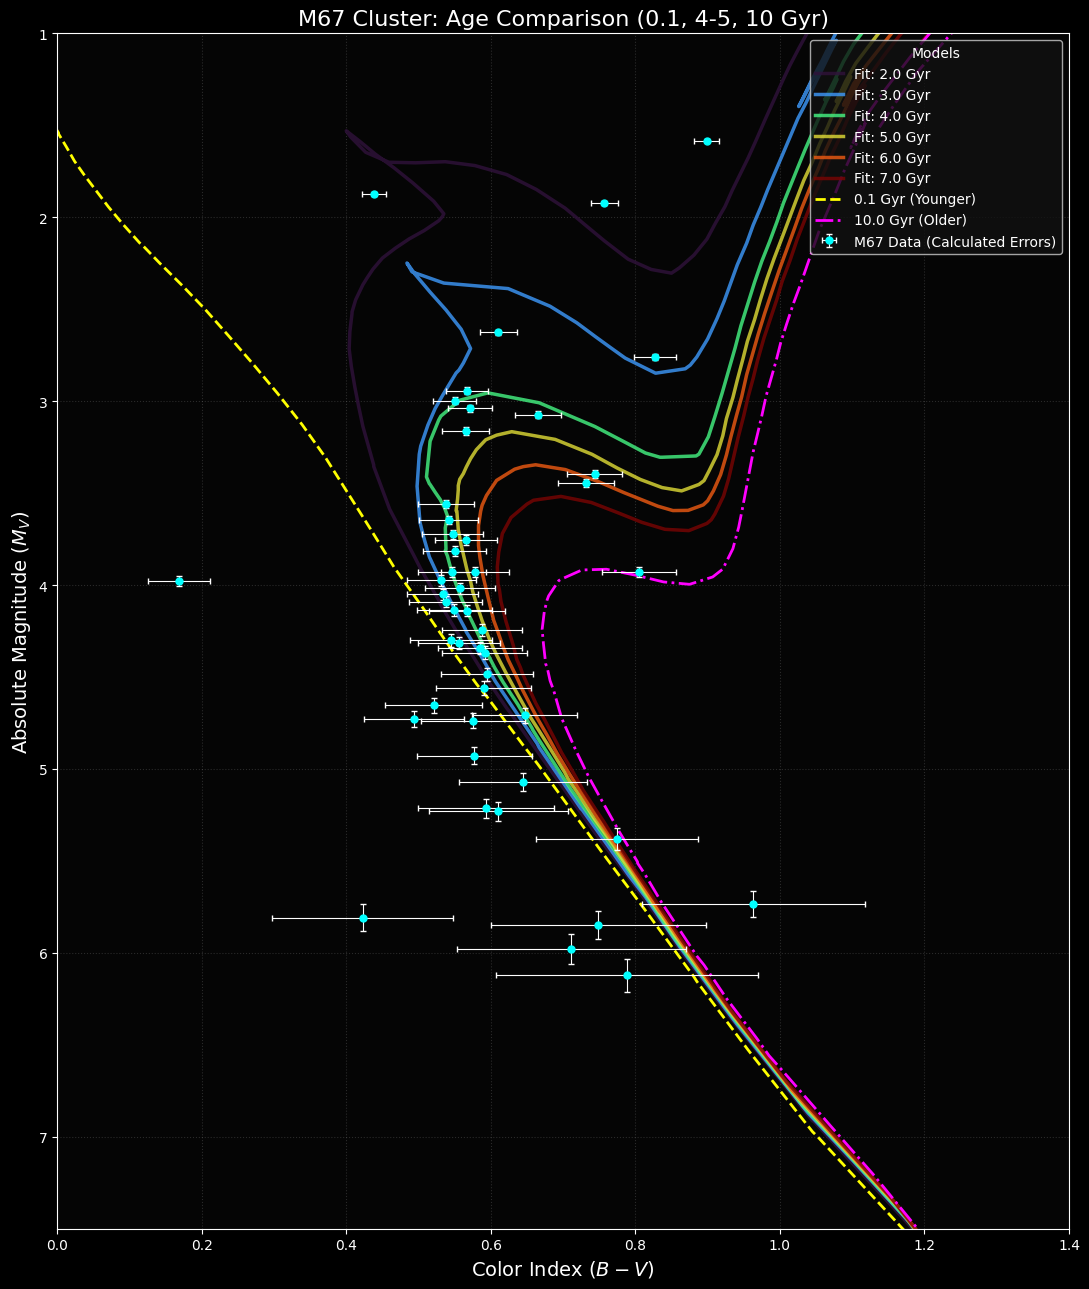

In [17]:
iso_path_main = "isochrone2.dat.txt"
iso_path_young = "100m.dat"
iso_path_old = "10b.dat"
gain = 0.24286

# (Assumes v_flux, b_flux, apertures, bkg_sigma, b_v_std, v_abs_mag are defined)
v_flux_err = np.sqrt(np.abs(v_flux) / gain + apertures.area * bkg_sigma**2)
b_flux_err = np.sqrt(np.abs(b_flux) / gain + apertures.area * bkg_sigma**2)

v_error = 1.0857 * (v_flux_err / np.abs(v_flux))
b_error = 1.0857 * (b_flux_err / np.abs(b_flux))
bv_error = np.sqrt(b_error**2 + v_error**2)

plt.figure(figsize=(11, 13))
plt.gca().set_facecolor('#050505')

plt.errorbar(b_v_std, v_abs_mag, xerr=bv_error, yerr=v_error,
             fmt='o', color='cyan', ecolor='white', elinewidth=0.8,
             capsize=2, markersize=5, label='M67 Data (Calculated Errors)', zorder=5)

try:
    data_main = np.genfromtxt(iso_path_main, names=True, skip_header=13, comments='#')
    log_ages_m = np.unique(data_main['logAge'])
    colors = plt.cm.turbo(np.linspace(0, 1, len(log_ages_m)))

    for i, log_age in enumerate(log_ages_m):
        mask = (data_main['logAge'] == log_age) & (data_main['label'] <= 3)
        v_p = data_main['Vmag'][mask]
        bv_p = data_main['Bmag'][mask] - data_main['Vmag'][mask]
        plt.plot(bv_p, v_p, color=colors[i], linewidth=2.5, alpha=0.8,
                 label=f'Fit: {10**log_age/1e9:.1f} Gyr')
except: print("Main isochrone file not found.")

try:
    data_y = np.genfromtxt(iso_path_young, names=True, skip_header=13, comments='#')
    mask_y = (data_y['label'] <= 3)
    plt.plot(data_y['Bmag'][mask_y] - data_y['Vmag'][mask_y], data_y['Vmag'][mask_y],
             '--', color='yellow', linewidth=2, label='0.1 Gyr (Younger)')
except: print("100m.dat not found.")

try:
    data_o = np.genfromtxt(iso_path_old, names=True, skip_header=13, comments='#')
    mask_o = (data_o['label'] <= 3)
    plt.plot(data_o['Bmag'][mask_o] - data_o['Vmag'][mask_o], data_o['Vmag'][mask_o],
             '-.', color='magenta', linewidth=2, label='10.0 Gyr (Older)')
except: print("10b.dat not found.")


plt.gca().invert_yaxis()
plt.xlabel("Color Index $(B - V)$", fontsize=14, color='white')
plt.ylabel("Absolute Magnitude $(M_V)$", fontsize=14, color='white')
plt.title("M67 Cluster: Age Comparison (0.1, 4-5, 10 Gyr)", fontsize=16, color='white')

plt.xlim(0.0, 1.4)
plt.ylim(7.5, 1.0)

plt.grid(color='gray', linestyle=':', alpha=0.3)
plt.legend(title="Models", loc='upper right', frameon=True, facecolor='#111111', labelcolor='white')
plt.tick_params(colors='white')
plt.tight_layout()
plt.show()

<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:25: SyntaxWarning: invalid escape sequence '\c'
<>:27: SyntaxWarning: invalid escape sequence '\c'
<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:25: SyntaxWarning: invalid escape sequence '\c'
<>:27: SyntaxWarning: invalid escape sequence '\c'
C:\Users\HP\AppData\Local\Temp\ipykernel_5952\1807355458.py:11: SyntaxWarning: invalid escape sequence '\c'
  marker='o', markersize=8, linewidth=2, label='$\chi^2$ Residuals', alpha=0.8)
C:\Users\HP\AppData\Local\Temp\ipykernel_5952\1807355458.py:19: SyntaxWarning: invalid escape sequence '\s'
  linewidth=1.5, label='1-$\sigma$ Bound ($\Delta\chi^2 \leq 1$)')
C:\Users\HP\AppData\Local\Temp\ipykernel_5952\1807355458.py:25: SyntaxWarning: invalid escape sequence '\c'
  plt.title('M67 Age Estimation: $\chi^2$ Minimization', color='white', fontsize=16)
C:\Users\HP\AppData\Local\Temp\ipyke

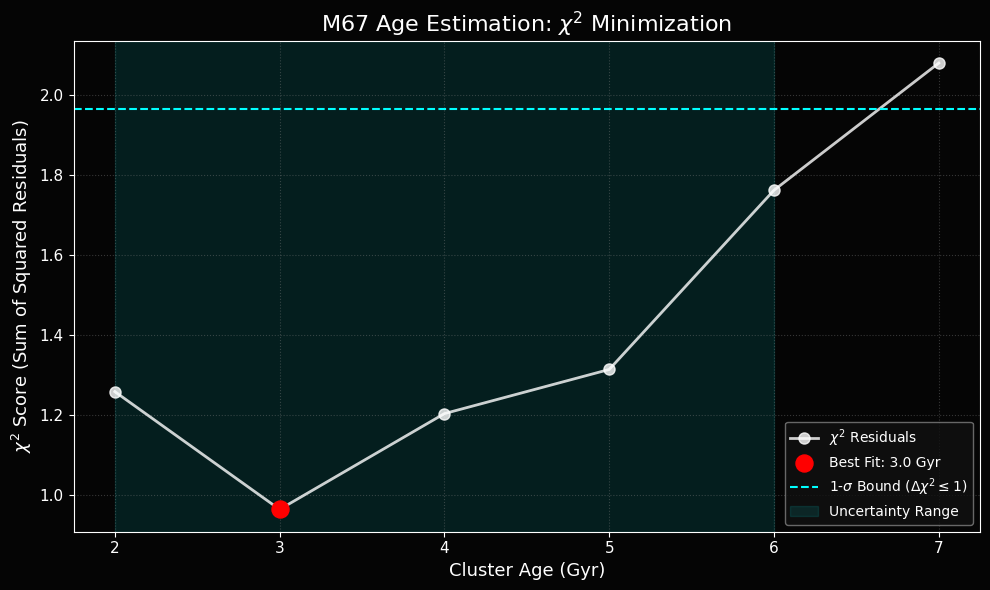

In [18]:
#I did this with AI, i asked it to give me the code for the graph of chi^2


plt.figure(figsize=(10, 6))
ax = plt.axes()
ax.set_facecolor('#050505') # Match your black theme
plt.gcf().set_facecolor('#050505')

# 1. Plot the raw Chi-Square values
plt.plot(score_df['age_gyr'], score_df['chi_sq'], color='white',
         marker='o', markersize=8, linewidth=2, label='$\chi^2$ Residuals', alpha=0.8)

# 2. Mark the Best Fit Point (The Minimum)
plt.scatter(best_fit_row['age_gyr'], best_fit_row['chi_sq'],
            color='red', s=150, zorder=5, label=f'Best Fit: {best_fit_row["age_gyr"]:.1f} Gyr')

# 3. Add the 1-Sigma Uncertainty Threshold
plt.axhline(y=sigma_threshold, color='cyan', linestyle='--',
            linewidth=1.5, label='1-$\sigma$ Bound ($\Delta\chi^2 \leq 1$)')

plt.axvspan(lower_bound, upper_bound, color='cyan', alpha=0.1, label='Uncertainty Range')

plt.title('M67 Age Estimation: $\chi^2$ Minimization', color='white', fontsize=16)
plt.xlabel('Cluster Age (Gyr)', color='white', fontsize=13)
plt.ylabel('$\chi^2$ Score (Sum of Squared Residuals)', color='white', fontsize=13)

plt.grid(color='gray', linestyle=':', alpha=0.4)
plt.tick_params(colors='white', labelsize=11)

# Add Legend
legend = plt.legend(facecolor='#111111', edgecolor='gray', labelcolor='white', fontsize=10)
legend.get_frame().set_alpha(0.8)

plt.tight_layout()
plt.savefig('chi_square_plot.png')
plt.show()